# C4: OpenEar ReAct Agent with Configurable Personas
**EECE 503P/798S Agentic Systems** · Tatiana Nohra

This builds on my C3 business agent (Maguy, OpenEar). C3 used Gemini's built-in function calling.
C4 replaces it with a **ReAct loop I wrote myself in LangGraph**: the model writes `Thought / Action / Action Input`
as plain text, my code parses it, runs the tool and feeds back an `Observation`.

## 1. Use case
| | |
|---|---|
| **Business** | OpenEar, a Lebanese online store for open-ear sports headphones (Stride, Pace Pro, Swim, Ultra, Sport Fit Kit) |
| **Agent goal** | Help athletes pick the right model for their sport, answer spec / delivery / policy questions, and take order requests |
| **Audience** | Runners, cyclists, swimmers and triathletes in Lebanon, writing in English, Arabic or Arabizi |
| **Tools** | `search_catalog`, `get_product`, `compare_products`, `delivery_quote`, `get_policy`, `record_customer_interest`, `record_feedback` |
| **Constraints** | Only facts from the business files (via tools) · delivery inside Lebanon only · never confirm an order or take card details · must ask the **colour** before recording a Stride / Pace Pro order · Swim and Ultra colours are not listed, so never invented |

In [11]:
import tools
tools.DRY_RUN = True   # demo leads/feedback in this notebook are not written to the real logs
from tools import *
from personas import PERSONAS
from prompts import INSTRUCTIONS, build_prompt
from react_agent import run_agent, parse_react, print_trace, GRAPH

## 2. Tools
The model never sees Python code, only this description in its system prompt.
Facts live in tools (not in the prompt), so the agent has to look them up, which is what makes the ReAct loop useful.

In [12]:
print(TOOL_DESCRIPTIONS)
print()
print(search_catalog("triathlon", 170))
print(delivery_quote("Tripoli", 79))
print(record_customer_interest("Rima", "rima@gmail.com", "Pace Pro"))   # no colour -> error forces the agent to ask

- search_catalog: recommend models for a sport. Input: {"sport": str, "budget": number or null}
- get_product: specs, price and colour options of one product. Input: {"name": str}
- compare_products: compare two products side by side. Input: {"a": str, "b": str}
- delivery_quote: delivery fee, grand total and delivery time. Input: {"city": str, "cart_total": number}
- get_policy: store policy. Input: {"topic": one of delivery, payment, warranty, returns, contact, charging,
  helmet, calls, testing, team}
- record_customer_interest: save an order request. Input: {"name": str, "email": str, "product": str,
  "color": str, "message": str}. Only call it once you have name, email, product AND colour
  (colour is required for Stride and Pace Pro).
- record_feedback: log a question the tools cannot answer, a complaint or a suggestion. Input: {"question": str}

{'sport': 'triathlon', 'budget': 170, 'matches': [{'name': 'OpenEar Swim', 'price': 159, 'best_for': ['swimming', 'triathlon', 'open w

## 3. Personas (prompt traits + matching LLM config)
Each persona has its **own task**. A router (reused from C3) picks the persona for each message:
recommend → Coach Maguy, specs → Ziad, order → Nour.

Note: Gemini rejects `presence_penalty` / `frequency_penalty` on every available model
("Penalty is not enabled for this model"). They stay in the design, and `llm.py` drops them and logs it.

In [13]:
for key, p in PERSONAS.items():
    print(f"=== {p['name']}  ({key}) ===")
    print("Task:", p["task"])
    print(p["traits"])
    print("Config:", p["config"])
    for param, why in p["why"].items():
        print(f"  - {param}: {why}")
    print()

=== Coach Maguy  (coach) ===
Task: Find the right headphones for the customer's sport and training.
You are Coach Maguy, OpenEar's running-coach-style advisor.
Tone: warm, energetic, encouraging, like a teammate at the start line.
Vocabulary: sporty and everyday (PBs, long runs, trail days); no technical jargon unless asked.
Response style: 2 to 4 short sentences, one clear recommendation, end with one question that moves the customer
forward (their sport, budget or colour).
Values: the customer's safety outdoors and honest advice; never upsell a model they don't need.
You match the customer's language: English, Arabic or Arabizi.
Config: {'temperature': 0.8, 'top_p': 0.95, 'top_k': 40, 'max_output_tokens': 600, 'presence_penalty': 0.4}
  - temperature: 0.8: varied, lively wording so the coach doesn't sound scripted.
  - top_p: 0.95: keeps a wide pool of words for a natural, chatty tone.
  - top_k: 40: enough options for variety without random words.
  - max_output_tokens: 600: room fo

## 4. Instructions block
- One purpose per rule (14 rules)
- Input and output stated explicitly at the top
- One worked example inside the block (marathon → Pace Pro → delivery to Jounieh → ask colour)
- **Persona vs instructions check:** personas only set tone and style; instructions set behaviour. Example: Coach
  "ends with a question" fits rule 14 ("persona's tone"); Tech "says when a number is not listed" matches rules 2–3.

In [14]:
print(INSTRUCTIONS)

## Instructions
Input you receive: the conversation so far, the customer's latest message, and the Thought / Action /
Observation steps you already took for this message.
Output you return: one step in the output format above (an Action, or a Final Answer).

1. Write one Action per step, then stop. Never write an Observation yourself.
2. State only facts that appear in an Observation or in the conversation.
3. Never invent prices, specs, colours, stock, delivery times, discounts or policies.
4. Look up a product with a tool before giving its price or specs.
4b. Look up delivery, payment, warranty, returns or contact with get_policy or delivery_quote before answering
    about them. Never answer a delivery question from memory.
5. Only help with OpenEar topics (products, choosing a model, orders, delivery, payment, warranty, returns,
   contact). Politely decline anything else.
6. If the customer has not said which sport they train for, ask before recommending a model.
7. When a custome

## 5. ReAct loop (LangGraph, no prebuilt agent)
```
route → reason → parse ──action──→ act ──→ reason      (loop, max 6 tool calls)
                       ──final───→ finish
                       ──invalid─→ fix ──→ reason      (format error fed back as an Observation)
                       ──limit───→ fallback
```
| Node | Role |
|---|---|
| `route` | C3 router, now choosing the persona |
| `reason` | one Gemini call, with `stop=["Observation:"]` so the model cannot invent tool results |
| `parse` | **detects the action**: regex for `Action:` + JSON input, or `Final Answer:` |
| `act` | runs the Python tool, appends `Observation: {...}` |
| `fix` | returns a format error to the model so it can retry |
| guards in `parse` | reject a final answer that says "recorded" without calling a record tool, or talks about delivery without checking a delivery tool |

In [15]:
print(GRAPH.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	route(route)
	reason(reason)
	parse(parse)
	act(act)
	fix(fix)
	finish(finish)
	fallback(fallback)
	__end__([<p>__end__</p>]):::last
	__start__ --> route;
	act --> reason;
	fix --> reason;
	parse -.-> act;
	parse -.-> fallback;
	parse -.-> finish;
	parse -.-> fix;
	reason --> parse;
	route --> reason;
	fallback --> __end__;
	finish --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [16]:
# The parser on its own (no API call)
print(parse_react('Thought: need specs\nAction: get_product\nAction Input: {"name": "Swim"}'))
print(parse_react('Thought: done\nFinal Answer: The Swim costs $159.'))
print(parse_react('Action: get_product\nAction Input: {"name": "Swim"}\nFinal Answer: made up'))  # action wins
print(parse_react('Action: fly_to_moon\nAction Input: {}'))

{'kind': 'action', 'tool': 'get_product', 'args': {'name': 'Swim'}, 'thought': 'need specs'}
{'kind': 'final', 'answer': 'The Swim costs $159.', 'thought': 'done'}
{'kind': 'action', 'tool': 'get_product', 'args': {'name': 'Swim'}, 'thought': ''}
{'kind': 'invalid', 'error': "Unknown tool 'fly_to_moon'. Available tools: search_catalog, get_product, compare_products, delivery_quote, get_policy, record_customer_interest, record_feedback."}


## 6. Live demo

In [17]:
history = []
for msg in ["I want the Pace Pro. I'm Rima, rima@gmail.com, I live in Tripoli", "red please"]:
    out = run_agent(msg, history, verbose=True)
    print(f"\n>>> {PERSONAS[out['persona']]['name']}: {out['final']}\n" + "-" * 80)
    history += [{"role": "user", "content": msg}, {"role": "assistant", "content": out["final"]}]

[ROUTE] order -> Nour, Order Desk
[LLM gemini-3.1-flash-lite]
Action: get_product
Action Input: {"name": "Pace Pro"}
Observation: {"name": "OpenEar Pace Pro", "price": 129, "conduction": "bone", "battery_h": 10, "ip": "IP67", "weight_g": 26, "colors": ["black", "red", "blue"], "best_for": ["serious running", "trail running", "cycling", "marathon"], "notes": "Most popular model. Secure wraparound fit, dual microphones for calls."}
[LLM gemini-3.1-flash-lite]
Thought: I have the product, price, name, email, and city. I still need the colour to complete the request for the Pace Pro.

Final Answer: Hello Rima, thank you for choosing the Pace Pro. It is a great choice for your activities. To proceed with your request, could you please let me know which colour you would prefer: black, red, or blue?

>>> Nour, Order Desk: Hello Rima, thank you for choosing the Pace Pro. It is a great choice for your activities. To proceed with your request, could you please let me know which colour you would 

In [18]:
out = run_agent("Do you ship to Dubai?", verbose=True)
print(f"\n>>> {PERSONAS[out['persona']]['name']}: {out['final']}")

[ROUTE] order -> Nour, Order Desk
[LLM gemini-3.1-flash-lite]
Thought: I need to check the delivery policy to see if we ship to Dubai.
Action: get_policy
Action Input: {"topic": "delivery"}
Observation: {"topic": "delivery", "policy": "Beirut and Mount Lebanon: within 24 hours. Rest of Lebanon: 2 to 3 days. Fee $4, free on orders over $100. Only delivers inside Lebanon. If a customer asks for delivery outside Lebanon, log it with record_feedback."}
[LLM gemini-3.1-flash-lite]
Thought: The delivery policy states that OpenEar only delivers within Lebanon. I need to inform the customer about this and log their request as feedback.

Action: record_feedback
Action Input: {"question": "Do you ship to Dubai?"}
Observation: {"status": "recorded", "type": "feedback", "tell_customer": "The team will follow up. Contact: support@openear.store or @openear.lb on Instagram."}
[LLM gemini-3.1-flash-lite]
Final Answer: I am sorry, but we currently only deliver within Lebanon. I have shared your request

## 7. Experiments
10 test questions × 12 setups, changing **one thing at a time** vs the baseline
(auto persona, CoT, zero-shot, system prompt, gemini-3.1-flash-lite).
Each run passes only if it called the right tools, included the right facts and invented nothing
(e.g. no colours for the Swim). Full log: `logs/experiments.jsonl`. Code: `experiments.py`, `summarize.py`.

In [19]:
import csv
from IPython.display import Markdown, display
rows = list(csv.DictReader(open("logs/results_final.csv", encoding="utf-8")))
cols = ["setup", "pass_rate", "tools_ok", "facts_ok", "no_hallucination", "format_errors", "avg_latency_s", "avg_words", "failed_cases"]
table = "| " + " | ".join(cols) + " |\n|" + "---|" * len(cols) + "\n"
table += "\n".join("| " + " | ".join(r[c] for c in cols) + " |" for r in rows)
display(Markdown(table))

| setup | pass_rate | tools_ok | facts_ok | no_hallucination | format_errors | avg_latency_s | avg_words | failed_cases |
|---|---|---|---|---|---|---|---|---|
| baseline | 1.0 | 1.0 | 1.0 | 1.0 | 1 | 11.0 | 33 |  |
| no_cot | 0.75 | 0.75 | 0.88 | 1.0 | 1 | 16.1 | 42 | dubai, order_done |
| few_shot | 1.0 | 1.0 | 1.0 | 1.0 | 0 | 25.5 | 35 |  |
| in_message | 1.0 | 1.0 | 1.0 | 1.0 | 0 | 31.1 | 36 |  |
| no_instructions | 0.8 | 0.9 | 0.8 | 1.0 | 0 | 34.8 | 41 | dubai, ask_colour |
| temp_0 | 0.9 | 1.0 | 0.9 | 1.0 | 2 | 17.1 | 40 | mtb_budget |
| temp_1.3 | 1.0 | 1.0 | 1.0 | 1.0 | 0 | 11.7 | 39 |  |
| top_p_0.3 | 0.8 | 1.0 | 0.8 | 1.0 | 2 | 19.5 | 37 | mtb_budget, ask_colour |
| model_3.5_flash | 1.0 | 1.0 | 1.0 | 1.0 | 2 | 39.7 | 44 |  |
| only_coach | 1.0 | 1.0 | 1.0 | 1.0 | 0 | 5.3 | 44 |  |
| only_tech | 1.0 | 1.0 | 1.0 | 1.0 | 1 | 8.9 | 34 |  |
| only_order | 0.9 | 1.0 | 0.9 | 1.0 | 5 | 10.0 | 43 | swim |

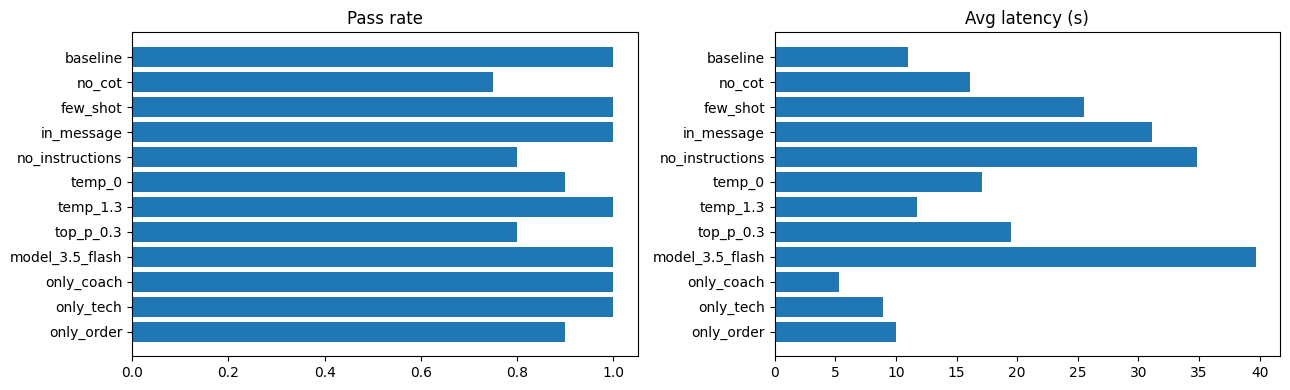

In [20]:
try:
    import matplotlib.pyplot as plt
    names = [r["setup"] for r in rows]
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].barh(names, [float(r["pass_rate"]) for r in rows]); ax[0].set_title("Pass rate"); ax[0].invert_yaxis()
    ax[1].barh(names, [float(r["avg_latency_s"]) for r in rows]); ax[1].set_title("Avg latency (s)"); ax[1].invert_yaxis()
    plt.tight_layout(); plt.show()
except ImportError:
    print("pip install matplotlib to see the chart")

## 8. Reflection

**1. Which persona gave the most helpful or natural results?**
It depends on the task, but overall Coach Maguy gave the most helpful and natural answers. She tailored her
advice to each customer's sport and budget, and she could still handle technical questions and the checkout
step, which doesn't need much expertise. In the experiments, when Maguy handled every question alone
(`only_coach`), she passed all 10 test cases and was the fastest persona (5.3 s on average). Her higher
temperature (0.8) made her sound warm and varied rather than scripted, and she always ended with a question
that moved the customer forward (their sport, budget or colour).

Ziad is useful for very technical questions that Maguy can't cover in as much depth: he answers with exact
numbers in short bullet points and gave the shortest replies (34 words on average, vs 44 for Maguy). He also
passed all 10 cases. But Ziad isn't a customer-oriented salesman; he is more of a technician, so his answers
feel cold for a customer who just wants a recommendation.

Nour was the most careful with orders: she always asked for the colour, checked the email and confirmed the
details back. But when she had to handle everything (`only_order`), she made the most format errors (5) and
failed the swimming recommendation, because choosing a model isn't her task.

So the most natural setup is not a single persona but letting the router send each question to the persona
built for it: Maguy for recommendations, Ziad for specs and Nour for orders.

**2. Which prompt and configuration combination performed best?**
The baseline (router + CoT + zero-shot + system prompt + gemini-3.1-flash-lite) got 10/10 at 11 s.
**2. Which prompt and configuration combination performed best?**

The baseline performed best: router + Chain-of-Thought + zero-shot + instructions in the system prompt +
gemini-3.1-flash-lite. It passed 10/10 test cases with an average of 11 s per answer.

- **CoT mattered most.** Without the `Thought:` step, the pass rate dropped to 0.6–0.75: the agent skipped
  tools (e.g. answered a comparison from memory) and forgot to record an order. Writing its reasoning first
  makes it decide which tool it needs before answering.
- **Few-shot and in-message instructions** also scored 10/10, but were 2–3× slower (25–31 s) because the
  prompt is longer. The worked example inside the instructions block was already enough.
- **gemini-3.5-flash** scored 10/10 too, but took 40 s per answer, so the bigger model added cost and delay
  without improving accuracy.
- **Removing the instructions block** dropped the pass rate to 0.8 (see Q4).
- **Very low temperature / top-p** (temperature 0, top-p 0.3) did not help: 0.8–0.9 with more format errors.
  I expected the most deterministic settings to be the most reliable, but at temperature 1.3 the agent still
  scored 10/10, because the tools and the strict output format keep the facts right whatever the sampling.
- **Penalties** (presence / frequency) could not be tested: every Gemini model on my key rejects them
  ("Penalty is not enabled for this model"), so the code drops them and logs it.

Caveat: each setup ran the 10 questions once, so one failure = 0.1 and differences of ±0.1 are noise.
Only no-CoT and no-instructions are clearly worse than the baseline.

**3. How well did the agent reason and use tools?**
Overall it reasoned well. In the baseline it picked the right tools in 10/10 cases, using 1.3 tool calls per
question on average, and it chained them correctly when a question needed several steps. For example, for an
order it called `get_product` → `delivery_quote` → `record_customer_interest`, and its Thought lines explained
each step ("I have the price, now I need the delivery cost for Hazmieh"). It also asked for the colour before
recording a Stride or Pace Pro order, never invented colours for the Swim or Ultra, and noticed an invalid
email (`tatianaohra5gmail`) and asked the customer to fix it.

It was not perfect, and testing exposed some failures that I fixed:
- **Pretending to act:** it once told the customer "I have recorded your request" without calling the tool,
  so no lead was saved. I added a guard in the parse node: a final answer that says "recorded" without a
  record tool call is rejected and sent back to the model.
- **Inventing facts:** it once said "Yes, we ship to Dubai!" without checking any tool. I added rule 4b and a
  second guard: no answer about delivery without calling `get_policy` or `delivery_quote` first.
- **Format slips:** sometimes it replied in plain text without "Final Answer:", or wrote an Action and a Final
  Answer in the same step. The parser treats a plain reply as the final answer, and when both appear it runs
  the Action first, so the answer is based on a real Observation.
- **Bad tool data, not bad reasoning:** "mountain biking" was matched to the Ultra because of a keyword in my
  catalog. The agent then reasoned correctly from the wrong Observation, which showed me that a ReAct agent is
  only as good as its tools.

**4. Did the instructions block change the agent's behaviour?**
Yes, noticeably. When I removed the instructions block and kept only the persona, the tools and the output
format (`no_instructions`), the pass rate dropped from 1.0 to 0.8. The two failures were exactly the cases that
depend on specific rules:
- **Dubai:** it checked the delivery policy and told the customer we only deliver in Lebanon, but did not log
  the request with `record_feedback` or share the support email (rule 11).
- **Colour:** when a customer said "I want the Pace Pro", it did not ask which colour (rule 7).

The general behaviour (picking tools, answering product questions) was the same without the instructions,
because the tool descriptions and the output format already guide that. The instructions mattered for the
business rules a model can't guess on its own. Replies were also longer without them (41 vs 33 words).

But instructions alone were not enough. Some rules only held reliably once I backed them up outside the
prompt:
- code guards in the parse node (no "recorded" without a record tool call, no delivery answer without
  checking a delivery tool)
- a colour check inside `record_customer_interest`, which returns an error if the colour is missing
- reminders inside tool outputs: `record_feedback` returns "tell the customer: support@openear.store", which
  the model followed more consistently than the same rule written in the prompt.

So the instructions shape the behaviour, but anything that must never go wrong should also be enforced in code.

**5. What were the biggest challenges in implementation?**
**Making the ReAct format reliable.** Because I parse plain text instead of using Gemini's built-in function
calling, every format slip breaks the loop. The model sometimes replied without "Final Answer:", wrote an
Action and a Final Answer in the same step, or started inventing its own "Observation:". I handled this with a
stop sequence on "Observation:" (so tool results can only come from my code), a lenient parser (a plain reply
counts as the final answer, and an Action always wins over a Final Answer in the same step), and a `fix` node
that sends format errors back to the model.

**The model inventing actions and facts.** The hardest bugs were not crashes but confident lies: "I have
recorded your request" with no tool call, and "Yes, we ship to Dubai" without checking. The instructions block
alone did not stop this; I needed code guards in the parse node and reminders inside tool outputs (see Q4).

**Gemini limitations.**
- Every available model rejects `presence_penalty` / `frequency_penalty`, so that part of the persona configs
  could not be tested.
- gemini-3.5-flash-lite often returned an empty `MALFORMED_RESPONSE` on my ReAct prompts, so I switched the
  default to gemini-3.1-flash-lite and added automatic fallback to the next model.

**Infrastructure.**
- One API request hung for about 3 hours because the client had no time limit; I added a 30 s timeout with
  retries.
- Google server errors (504 / timeouts) were first counted as agent failures and made some setups look broken.
  I changed the experiment script to retry them and report API errors separately from the pass rate.
- The free tier allows 500 requests per day per model. The full experiment (12 setups × 10 questions, ~3 calls
  each) plus my manual testing used it up halfway through, so I had to finish the runs with a new API key.